<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/QBoost_CANBusIntrusion_Caivano2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QBoost (quantum-annealing ensemble) for fast CAN bus intrusion detection: Caivano et al. (2022) step by step

This notebook re-implements, runs and checks the method of

> Danilo Caivano, Mirko De Vincentiis, Federica Nitti and Anibrata Pal,
> "Quantum Optimization for Fast CAN Bus Intrusion Detection",
> 1st International Workshop on Quantum Programming for Software Engineering (QP4SE '22), ACM, 2022.
> https://doi.org/10.1145/3549036.3562058

The paper trains **QBoost** (Neven et al., 2008/2012): an ensemble of weak classifiers in which *choosing which weak
classifiers to keep* is written as a **QUBO** (quadratic unconstrained binary optimisation) problem. The authors sent that
QUBO to a **D-Wave Leap hybrid quantum-annealing solver** and compared the result with a scikit-learn `SVC` on two attack
logs of the HCRL **Car-Hacking dataset** (DoS and Fuzzy). Nobody can rerun a D-Wave cloud job from a free Colab, so this
notebook builds **the same QUBO** and solves it with **simulated annealing** (`dwave-samplers`, a classical stand-in for the
annealer; a tiny instance is also checked against exhaustive enumeration). Everything else (CAN preprocessing, Frequency
feature, one-hot and binary encoding, 80/20 split, 10 shuffled rounds, SVC baseline, accuracy / precision / recall / F1,
confusion matrices, training and prediction times) follows the paper.

**What the notebook does.**
1. Downloads the real Car-Hacking `DoS_dataset.csv` and `Fuzzy_dataset.csv` (3.6 and 3.8 million CAN frames) from a public mirror.
2. Rebuilds the paper's features (time between frames with the same ID, one-hot / binary encoded ID and payload).
3. Trains **QBoost with a simulated-annealing QUBO solver** and **SVC**, plus RandomForest and AdaBoost as extra baselines.
4. Re-draws the paper's Tables 1 to 3 and Fig. 2, adds a training-set-size scaling study of the timing claim and a
   leakage-free ("strict") feature-encoding variant, and ends with a claim-by-claim verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
`dwave-samplers` (everything else is preinstalled on Colab). No GPU and no D-Wave account are needed.

**Runtime.** `FAST_MODE = True` (20,000 frames per round, 3 rounds) takes about 5 to 8 minutes on a CPU (most of it is
parsing the two big CSV files once). `FAST_MODE = False` (50,000 frames per round, the paper's 10 rounds) is the full run;
its measured duration is written in the section "Runtime" at the end.

**What you get at the end.** Tables of accuracy / precision / recall / F1 for train and test sets next to the paper's
Table 3, the paper's timing Tables 1 and 2 re-measured, confusion matrices (paper's Fig. 2 layout), a timing-vs-data-size
plot with an extrapolation to the paper's data size, and an honest verdict on every claim that can be checked.

## The paper in one page

**Problem.** The CAN bus connecting a car's ECUs has no authentication, so an attacker can inject frames. Classical IDS
models (SVM and others) are too slow for real-time use on millions of frames; the paper asks whether a quantum-annealing
classifier is faster at similar accuracy.

**Decision.** Binary: a CAN frame is *malicious* (`T` in the dataset, label -1) or *normal* (`R`, label +1).

**Data (Section 4.2).** HCRL **Car-Hacking dataset** (Song, Woo and Kim, 2020): CAN frames logged through the OBD-II port of a
real car during message-injection attacks. Two attack files are used. *DoS*: frames with the dominant ID `0000` and an empty
payload every 0.3 ms. *Fuzzy*: random ID and random payload every 0.5 ms. More than 3.5 million frames per file. Fields:
timestamp, CAN ID (hex), DLC, DATA[0-7] (hex), label.

**Pipeline (Section 4.1, Fig. 1).**
1. *Pre-processing*: drop frames with `DLC != 8`; derive **Frequency** = milliseconds since the previous frame with the same
   ID; one-hot encode the CAN ID and **binary-encode** the payload string (DoS: 43 features in total); in the Fuzzy file both
   ID (11 features) and payload (20 features) are binary-encoded (32 features in total); MinMax scaling; labels R -> +1, T -> -1.
2. *Split*: shuffle, 80 % train / 20 % test, repeated in **10 rounds**.
3. *Models* (one per attack file): **QBoost on D-Wave Leap hybrid solvers** and **scikit-learn SVC**.

**QBoost.** The strong classifier is `H(x) = sign( (1/K) * sum_i w_i h_i(x) )` with weak classifiers `h_i(x) in {-1,+1}` and
*binary* weights `w_i in {0,1}`. The weights minimise the squared deviation from the labels plus a penalty `lambda * sum_i w_i`
on the number of selected weak classifiers. This is a QUBO in the `w_i`, which is what an annealer minimises.

**Claims.**

| Claim | Paper value |
|---|---|
| DoS: SVC and QBoost both perfect on train and test (accuracy, precision, recall, F1), in each of 10 rounds | 1.0 (Table 3) |
| Fuzzy test, SVC (accuracy / precision / recall / F1) | 0.9716 / 0.9785 / 0.9892 / 0.9838 (Table 3) |
| Fuzzy test, QBoost | 0.9756 / 0.9959 / 0.9760 / 0.9858 (Table 3) |
| Fuzzy train, SVC / QBoost accuracy | 0.9858 / 0.9778 (Table 3) |
| SVC recall slightly better than QBoost on Fuzzy | 0.9892 vs 0.9760 |
| DoS time, SVC vs QBoost (train s / predict s) | 68.67 / 2.561 vs 26.14 / 0.0275; gains 62 % and 99 % (Table 1) |
| Fuzzy time, SVC vs QBoost (train s / predict s) | 5933.3 / 431.46 vs 25.71 / 0.146; gains 99 % and 99 % (Table 2) |
| Feature counts | DoS 43, Fuzzy 32 |

Metrics in the paper's Table 3 treat **normal (+1) as the positive class**; this notebook follows that convention for the
paper comparison and also reports attack-as-positive numbers.

### What follows the paper and what had to be chosen

The paper does not say which weak classifiers QBoost used, how many, which lambda, how the annealer was configured, nor how
many frames the timed runs used. Everything unspecified is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Quantum solver | D-Wave Leap hybrid solver (cloud) | `dwave-samplers` **simulated annealing** on the same QUBO (`# CHOICE`); exhaustive check on a 16-variable QUBO |
| Weak classifiers | not stated | pool of `K_POOL` shallow decision trees (depth 3), each trained on a random subset of `TREE_ROWS` training frames and random features (`# CHOICE`); depth-1 stumps (Neven's original) run as an ablation |
| Sparsity weight lambda | not stated | chosen from a grid on a validation part of the training split (`# CHOICE`) |
| Weights | binary | binary (QUBO variables) |
| Data | full DoS (3.6 M) and Fuzzy (3.8 M) frames | the same files, but each round draws a **random sample of `N_TOTAL` frames** (20 k in FAST, 50 k in full mode), because an RBF-SVC on 3 M frames takes hours on a CPU and the paper's own SVC needed 1.6 h (`# CHOICE`) |
| Frequency of the first frame of an ID | not stated | set to 0 (`# CHOICE`) |
| Rows with DLC != 8 | removed | removed (`DoS`: 3,634,583 left, `Fuzzy`: 3,751,024) |
| Encoding | one-hot (ID) + binary (payload) for DoS, binary for both for Fuzzy | the same. The binary code is the **order of first appearance** of each ID / payload string in the whole log (what a `BinaryEncoder` fitted on the whole file does). It uses no labels, but it is fitted before the split, so a second variant fitted **on the training split only** is run (`strict`) |
| Scaling | MinMax | MinMax fitted on the training split only, test values clipped to [0, 1] |
| Split | 80 / 20 shuffled, 10 rounds | stratified 80 / 20, `ROUNDS` rounds with a different shuffle each round |
| SVC | scikit-learn `SVC` | `SVC()` with defaults (RBF, C = 1) (`# CHOICE`: the paper gives no hyper-parameters) |
| Timing | D-Wave cloud wall time vs SVC on the full data | local CPU wall time at the sample sizes above, plus a scaling study and an **extrapolation** to the paper's data size |
| Extra baselines | none (RF / AdaBoost named as future work) | RandomForest and AdaBoost on identical inputs |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line only runs on Colab or where dwave-samplers is missing; a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("dwave.samplers") is None:
    %pip install -q "dimod==0.12.22" "dwave-samplers==1.8.0"
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo in about 5 to 8 minutes. False: the paper's 10 rounds on larger samples.
SEED      = 42              # CHOICE: the paper gives no seed

TEST_SIZE = 0.2             # paper: 80 % train / 20 % test
if FAST_MODE:
    N_TOTAL      = 20_000   # frames drawn per round (train + test)
    ROUNDS       = 3        # paper: 10 shuffled rounds
    STRICT_ROUNDS = 1       # rounds for the train-only-encoding variant
    K_POOL       = 60       # number of weak classifiers = number of QUBO variables
    SA_READS     = 30       # independent annealing runs per QUBO
    LAMBDAS      = [1e-3, 3e-3, 1e-2, 3e-2]
    SCALE_SIZES  = [2_000, 4_000, 8_000, 16_000]       # training-set sizes of the timing study
else:
    N_TOTAL      = 50_000
    ROUNDS       = 10
    STRICT_ROUNDS = 3
    K_POOL       = 100
    SA_READS     = 50
    LAMBDAS      = [1e-4, 1e-3, 3e-3, 1e-2, 3e-2]
    SCALE_SIZES  = [2_500, 5_000, 10_000, 20_000, 40_000]

TREE_ROWS   = 5_000         # CHOICE: training frames seen by each weak tree (fixed, so pool training does not grow with the data)
TREE_DEPTH  = 3             # CHOICE: depth of the weak trees of the main QBoost; depth 1 (stumps) is the ablation
SA_SWEEPS   = 1_000         # sweeps per annealing read (dwave-samplers default)
VAL_FRAC    = 0.2           # share of the training split used to choose lambda
N_PRED_TIME = 5_000         # number of test frames used for the prediction-time measurements of the scaling study

DATA_DIR    = "car_hacking_data"   # cache (relative to the working directory)
LOCAL_CSV_DIR = ""          # optional: folder that already holds DoS_dataset.csv and Fuzzy_dataset.csv
IBM_TOKEN   = ""            # unused here (kept for template compatibility); no quantum hardware is needed

GITHUB_ZIP  = "https://raw.githubusercontent.com/JehadAlyateem/Car-Hacking-Dataset/main/Car-Hacking-Dataset-1.zip"   # 66 MB mirror
DROPBOX_ZIP = ("https://www.dropbox.com/scl/fo/9rwsf9pclhvv9xxloojom/AF7JeRW893grZkigkulkAHk"
               "?rlkey=3h6zamu3kc262lrnipu5qden8&dl=1")   # official HCRL folder (about 950 MB, fallback)

# The paper's numbers (Tables 1 to 3), used in the final comparison
PAPER_T3 = {   # (dataset, split, classifier) -> (accuracy, precision, recall, F1); normal = positive class
    ("DoS", "Train", "SVC"): (1.0, 1.0, 1.0, 1.0), ("DoS", "Train", "QBoost"): (1.0, 1.0, 1.0, 1.0),
    ("DoS", "Test", "SVC"): (1.0, 1.0, 1.0, 1.0),  ("DoS", "Test", "QBoost"): (1.0, 1.0, 1.0, 1.0),
    ("Fuzzy", "Train", "SVC"): (0.9858, 0.9945, 0.9891, 0.9918), ("Fuzzy", "Train", "QBoost"): (0.9778, 0.9988, 0.9757, 0.9871),
    ("Fuzzy", "Test", "SVC"): (0.9716, 0.9785, 0.9892, 0.9838),  ("Fuzzy", "Test", "QBoost"): (0.9756, 0.9959, 0.9760, 0.9858),
}
PAPER_TIME = {  # dataset -> {classifier: (train s, predict s)}
    "DoS":   {"SVC": (68.6735, 2.5609),   "QBoost": (26.1415, 0.0275)},
    "Fuzzy": {"SVC": (5933.2840, 431.4609), "QBoost": (25.7134, 0.1462)},
}
PAPER_FEATURES = {"DoS": 43, "Fuzzy": 32}
PAPER_ATTACK_FRAMES = {"DoS": 587_521, "Fuzzy": 491_847}   # injected frames, from the HCRL dataset description

In [3]:
import os, io, time, zipfile, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import sklearn, dimod, dwave.samplers
from dwave.samplers import SimulatedAnnealingSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("dimod", dimod.__version__, "| dwave-samplers", dwave.samplers.__version__)
print("FAST_MODE =", FAST_MODE, "| N_TOTAL =", N_TOTAL, "| ROUNDS =", ROUNDS, "| K_POOL =", K_POOL, "| SA_READS =", SA_READS)
T_NOTEBOOK_START = time.time()

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
dimod 0.12.22 | dwave-samplers 1.8.0
FAST_MODE = False | N_TOTAL = 50000 | ROUNDS = 10 | K_POOL = 100 | SA_READS = 50


## 1. The Car-Hacking dataset

The HCRL (Korea University) **Car-Hacking dataset** was recorded through the OBD-II port of a real car. Every line of
`DoS_dataset.csv` / `Fuzzy_dataset.csv` is one CAN frame:

`timestamp, CAN ID (hex), DLC, DATA[0] ... DATA[DLC-1] (hex), flag`

where `flag` is `R` (regular frame) or `T` (injected frame). Frames with `DLC < 8` have fewer data columns, so the flag sits in
a different column: the parser below reads every line into 12 columns and keeps only `DLC = 8` frames, exactly the paper's
first pre-processing step.

The two files are in a public GitHub mirror (66 MB zip). If that fails, the official HCRL Dropbox folder (about 950 MB, all
attack types) is downloaded instead; or put the two CSVs in `LOCAL_CSV_DIR`. The parsed arrays are cached in `DATA_DIR` as
compact `.npz` files, so a second run does not parse again.

In [4]:
def download(url, dest, chunk=1 << 20):
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as fh:
            for part in r.iter_content(chunk):
                fh.write(part)

def ensure_csvs():
    """Return {name: path of the CSV}, downloading the files if they are not cached."""
    wanted = {"DoS": "DoS_dataset.csv", "Fuzzy": "Fuzzy_dataset.csv"}
    for folder in ([LOCAL_CSV_DIR] if LOCAL_CSV_DIR else []) + [DATA_DIR]:
        if all(os.path.exists(os.path.join(folder, f)) for f in wanted.values()):
            return {k: os.path.join(folder, f) for k, f in wanted.items()}
    for label, url in [("GitHub mirror", GITHUB_ZIP), ("official HCRL Dropbox folder", DROPBOX_ZIP)]:
        try:
            zpath = os.path.join(DATA_DIR, "download.zip")
            print(f"downloading from the {label} ...", flush=True); t0 = time.time()
            download(url, zpath)
            with zipfile.ZipFile(zpath) as z:
                for member in z.namelist():
                    base = os.path.basename(member)
                    if base in wanted.values():
                        with z.open(member) as src, open(os.path.join(DATA_DIR, base), "wb") as dst:
                            while True:
                                b = src.read(1 << 20)
                                if not b: break
                                dst.write(b)
            os.remove(zpath)
            if all(os.path.exists(os.path.join(DATA_DIR, f)) for f in wanted.values()):
                print(f"  done in {time.time() - t0:.0f} s"); break
        except Exception as e:
            print(f"  {label} failed: {e!r}")
    else:
        raise RuntimeError("could not obtain the Car-Hacking CSV files; set LOCAL_CSV_DIR to a folder that holds them")
    return {k: os.path.join(DATA_DIR, f) for k, f in wanted.items()}

def parse_csv(path):
    """One pass over the CSV: keep DLC = 8 frames; return timestamp, CAN id, 8-byte payload (uint64), attack flag (1 = T)."""
    cols = ["ts", "can_id", "dlc"] + [f"d{i}" for i in range(8)] + ["flag"]
    dt = {c: "category" for c in cols[1:]}; dt["ts"] = "float64"
    df = pd.read_csv(path, header=None, names=cols, dtype=dt, engine="c")
    n_raw = len(df)
    df = df[df["dlc"].astype(str) == "8"]
    df = df[df["flag"].notna()]                      # a DLC-8 line always has 12 fields
    def hexcol(s):
        lut = np.array([int(c, 16) if c not in ("R", "T") else -1 for c in s.cat.categories], dtype=np.int64)
        return lut[s.cat.codes.to_numpy()]
    cid = hexcol(df["can_id"])
    data = np.zeros(len(df), dtype=np.uint64)
    for i in range(8):
        data = (data << np.uint64(8)) | hexcol(df[f"d{i}"]).astype(np.uint64)
    y = (df["flag"].astype(str).to_numpy() == "T").astype(np.int8)       # 1 = injected (malicious)
    return df["ts"].to_numpy(), cid, data, y, n_raw

t0 = time.time()
CSV = ensure_csvs()
RAW = {}
for name in ["DoS", "Fuzzy"]:
    cache = os.path.join(DATA_DIR, f"{name}_parsed.npz")
    if os.path.exists(cache):
        z = np.load(cache); RAW[name] = dict(ts=z["ts"], cid=z["cid"], data=z["data"], y=z["y"], n_raw=int(z["n_raw"]))
    else:
        ts, cid, data, y, n_raw = parse_csv(CSV[name])
        np.savez_compressed(cache, ts=ts, cid=cid, data=data, y=y, n_raw=n_raw)
        RAW[name] = dict(ts=ts, cid=cid, data=data, y=y, n_raw=n_raw)
    print(f"{name}: parsed in {time.time() - t0:.0f} s (cumulative)")

rows = []
for name, R in RAW.items():
    rows.append(dict(dataset=name, frames_in_file=R["n_raw"], frames_DLC8=len(R["y"]), injected=int(R["y"].sum()),
                     injected_share=round(float(R["y"].mean()), 4), unique_IDs=len(np.unique(R["cid"])),
                     unique_payloads=len(np.unique(R["data"])), paper_injected=PAPER_ATTACK_FRAMES[name]))
display(pd.DataFrame(rows))

DoS: parsed in 1 s (cumulative)


Fuzzy: parsed in 3 s (cumulative)


,dataset,frames_in_file,frames_DLC8,injected,injected_share,unique_IDs,unique_payloads,paper_injected
0,DoS,3665771,3634583,587521,0.1616,26,66913,587521
1,Fuzzy,3838860,3751024,491847,0.1311,2048,560012,491847


The injected-frame counts match the HCRL description (587,521 for DoS, 491,847 for Fuzzy), so the mirror is the genuine
dataset. The DoS file has 26 distinct IDs (25 normal ones plus the attack ID `0000`), the Fuzzy file about 2,000.
The 17 and 20 bits needed to give every distinct payload string a binary code are what the paper means by "20 features"
for the Fuzzy payload.

## 2. Feature extraction (paper Section 4.1)

* **Frequency**: milliseconds between a frame and the previous frame with the **same ID**. This is a causal quantity
  (it only looks backwards) and uses no label. The first frame of every ID has no predecessor and gets 0 (`# CHOICE`).
* **ID** and **payload** are categorical. DoS: one-hot ID plus binary-coded payload. Fuzzy: binary-coded ID and payload.
  *Binary coding* gives each distinct category an integer (here: order of first appearance in the log, like a
  `BinaryEncoder`) and writes the integer in bits, one feature per bit.

The picture shows why Frequency matters: in the DoS file the injected frames arrive every 0.3 ms, much faster than any
normal ID.

,dataset,features_here,features_paper,ID_encoding,payload_bits
0,DoS,44,43,one-hot (26),17
1,Fuzzy,32,32,binary (11 bits),20


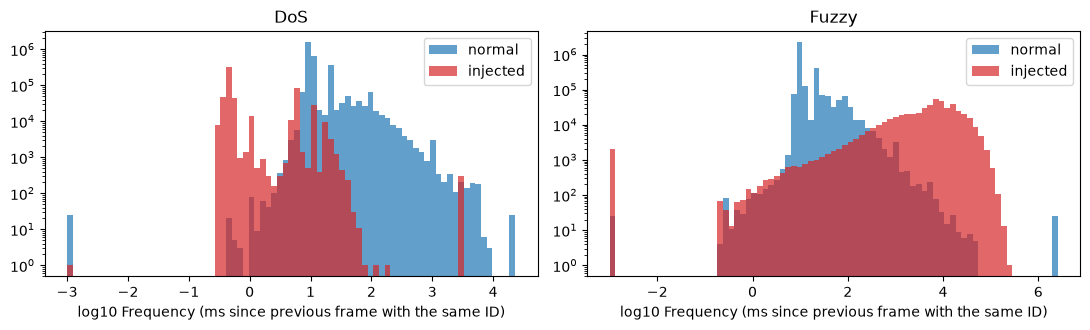

In [5]:
def bits(code, nb):
    return ((code[:, None] >> np.arange(nb)) & 1).astype(np.float32)

def first_appearance_codes(values):
    """integer code = rank of first appearance of each distinct value (label-free)"""
    _, idx, inv = np.unique(values, return_index=True, return_inverse=True)
    rank = np.empty(len(idx), dtype=np.int64); rank[np.argsort(idx)] = np.arange(len(idx))
    return rank[inv]

def prepare(name, R):
    ts, cid, data, y = R["ts"], R["cid"], R["data"], R["y"]
    # Frequency: ms since the previous frame with the same ID (stable sort by ID keeps the time order inside each ID)
    order = np.lexsort((np.arange(len(cid)), cid))
    t, c = ts[order], cid[order]
    d = np.zeros(len(ts)); d[1:] = np.diff(t) * 1000.0
    d[np.r_[True, c[1:] != c[:-1]]] = 0.0                    # CHOICE: first frame of an ID -> 0
    freq = np.empty(len(ts)); freq[order] = d
    P = dict(name=name, freq=freq, cid=cid, y=y.astype(int), ids=np.unique(cid),
             cc=first_appearance_codes(cid), dc=first_appearance_codes(data))
    P["nb_c"] = int(P["cc"].max()).bit_length(); P["nb_d"] = int(P["dc"].max()).bit_length()
    P["n_features_paper_style"] = 1 + (len(P["ids"]) if name == "DoS" else P["nb_c"]) + P["nb_d"]
    return P

PREP = {name: prepare(name, R) for name, R in RAW.items()}
display(pd.DataFrame([dict(dataset=n, features_here=P["n_features_paper_style"], features_paper=PAPER_FEATURES[n],
                           ID_encoding="one-hot (%d)" % len(P["ids"]) if n == "DoS" else "binary (%d bits)" % P["nb_c"],
                           payload_bits=P["nb_d"]) for n, P in PREP.items()]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, (n, P) in zip(ax, PREP.items()):
    f = np.log10(np.maximum(P["freq"], 1e-3))
    bins = np.linspace(-3, max(f.max(), 3), 80)
    a.hist(f[P["y"] == 0], bins=bins, alpha=.7, label="normal", color="tab:blue")
    a.hist(f[P["y"] == 1], bins=bins, alpha=.7, label="injected", color="tab:red")
    a.set_yscale("log"); a.set_xlabel("log10 Frequency (ms since previous frame with the same ID)"); a.set_title(f"{n}"); a.legend()
plt.tight_layout(); plt.show()

The DoS feature count is one more than the paper's 43 (we find 26 IDs, 17 payload bits, Frequency = 44; the paper counts 25
IDs, or 16 payload bits). The Fuzzy count (1 + 11 + 20 = 32) matches exactly.

## 3. Split, scaling and the design matrix

Each round draws `N_TOTAL` frames at random from the whole log (`# CHOICE`, see the table at the top), splits them 80 / 20
(stratified), builds the feature matrix and fits `MinMaxScaler` **on the training part only**; test values are clipped to [0, 1].

Two encodings are provided:

* `paper`: the binary codes are first-appearance ranks over the **whole** log, as when a `BinaryEncoder` is fitted on the full
  file before splitting. No label is involved, but frames of the test split influence the numbering.
* `strict`: IDs and payloads are numbered **using the training frames only**; a test value never seen in training gets one
  reserved code (all bits 1). This is leakage-free and is run as a robustness check.

In [6]:
def design_matrix(P, tr_idx, te_idx, mode="paper"):
    """Unscaled feature matrices for the training and test frames (indices into the whole log)."""
    name = P["name"]
    if mode == "paper":
        def f(idx):
            cf = (P["cid"][idx][:, None] == P["ids"][None, :]).astype(np.float32) if name == "DoS" else bits(P["cc"][idx], P["nb_c"])
            return np.hstack([P["freq"][idx][:, None], cf, bits(P["dc"][idx], P["nb_d"])])
        return f(tr_idx), f(te_idx)
    # strict: categories numbered on the training frames only; unseen test categories -> reserved all-ones code
    def codes(v_tr, v_te):
        c_tr, uniq = pd.factorize(v_tr)
        nb = int(np.ceil(np.log2(len(uniq) + 2)))
        c_te = pd.Index(uniq).get_indexer(v_te); c_te = np.where(c_te < 0, (1 << nb) - 1, c_te)
        return c_tr.astype(np.int64), c_te.astype(np.int64), nb
    cid, data = RAW[name]["cid"], RAW[name]["data"]
    dtr, dte, nbd = codes(data[tr_idx], data[te_idx])
    if name == "DoS":
        ids = np.unique(cid[tr_idx])
        ctr = (cid[tr_idx][:, None] == ids[None, :]).astype(np.float32); cte = (cid[te_idx][:, None] == ids[None, :]).astype(np.float32)
    else:
        a, b, nbc = codes(cid[tr_idx], cid[te_idx]); ctr, cte = bits(a, nbc), bits(b, nbc)
    return (np.hstack([P["freq"][tr_idx][:, None], ctr, bits(dtr, nbd)]),
            np.hstack([P["freq"][te_idx][:, None], cte, bits(dte, nbd)]))

def make_round(name, n_total, round_seed, mode="paper"):
    """Shuffle, draw n_total frames, 80/20 stratified split, scale on the training part only."""
    P = PREP[name]; r = np.random.default_rng(round_seed)
    pick = r.choice(len(P["y"]), size=n_total, replace=False)
    tr, te = train_test_split(pick, test_size=TEST_SIZE, random_state=round_seed, stratify=P["y"][pick])
    Xtr, Xte = design_matrix(P, tr, te, mode)
    sc = MinMaxScaler().fit(Xtr)                                  # fitted on the training split only
    return sc.transform(Xtr), np.clip(sc.transform(Xte), 0, 1), P["y"][tr], P["y"][te]

Xtr, Xte, ytr, yte = make_round("Fuzzy", N_TOTAL, SEED)
print("Fuzzy example round:", Xtr.shape, Xte.shape, "attack share train/test: %.3f / %.3f" % (ytr.mean(), yte.mean()))

Fuzzy example round: (40000, 32) (10000, 32) attack share train/test: 0.131 / 0.131


## Dataset Exploration and Visualisation

What the data look like before any model sees them. All numbers below come from the real Car-Hacking logs.

* **Shape**: one row per CAN frame (after dropping `DLC != 8` frames); the design matrix has one column per feature
  (`Frequency`, the ID columns and the payload bits).
* **Original labels**: the dataset has exactly two labels, `R` (regular frame) and `T` (injected frame). There are no
  separate attack sub-classes inside one file; DoS and Fuzzy are two different attacks, each in its own file.
* **2-D scatter**: raw PCA coordinates (PCA fitted on the training split of one round, on the MinMax-scaled features) of
  real test frames, coloured by their ground-truth label. This method does not use angle encoding, so the coordinates are
  not rescaled to [0, pi].

,dataset,frames,n_features,first_features
0,DoS,3634583,44,"Frequency_ms, ID=0x000, ID=0x002, ... , payloa..."
1,Fuzzy,3751024,32,"Frequency_ms, ID_bit0, ID_bit1, ... , payload_..."


,dataset,original_label,frames,share
0,DoS,"R (regular, normal)",3047062,0.8384
1,DoS,"T (injected, malicious)",587521,0.1616
2,Fuzzy,"R (regular, normal)",3259177,0.8689
3,Fuzzy,"T (injected, malicious)",491847,0.1311


feature names, DoS   : ['Frequency_ms', 'ID=0x000', 'ID=0x002', 'ID=0x0a0', 'ID=0x0a1', 'ID=0x130', 'ID=0x131', 'ID=0x140', 'ID=0x153', 'ID=0x18f', 'ID=0x1f1', 'ID=0x260', 'ID=0x2a0', 'ID=0x2c0', 'ID=0x316', 'ID=0x329', 'ID=0x350', 'ID=0x370', 'ID=0x430', 'ID=0x43f', 'ID=0x440', 'ID=0x4b1', 'ID=0x4f0', 'ID=0x545', 'ID=0x5a0', 'ID=0x5a2', 'ID=0x690', 'payload_bit0', 'payload_bit1', 'payload_bit2', 'payload_bit3', 'payload_bit4', 'payload_bit5', 'payload_bit6', 'payload_bit7', 'payload_bit8', 'payload_bit9', 'payload_bit10', 'payload_bit11', 'payload_bit12', 'payload_bit13', 'payload_bit14', 'payload_bit15', 'payload_bit16']
feature names, Fuzzy : ['Frequency_ms', 'ID_bit0', 'ID_bit1', 'ID_bit2', 'ID_bit3', 'ID_bit4', 'ID_bit5', 'ID_bit6', 'ID_bit7', 'ID_bit8', 'ID_bit9', 'ID_bit10', 'payload_bit0', 'payload_bit1', 'payload_bit2', 'payload_bit3', 'payload_bit4', 'payload_bit5', 'payload_bit6', 'payload_bit7', 'payload_bit8', 'payload_bit9', 'payload_bit10', 'payload_bit11', 'payload_bit1

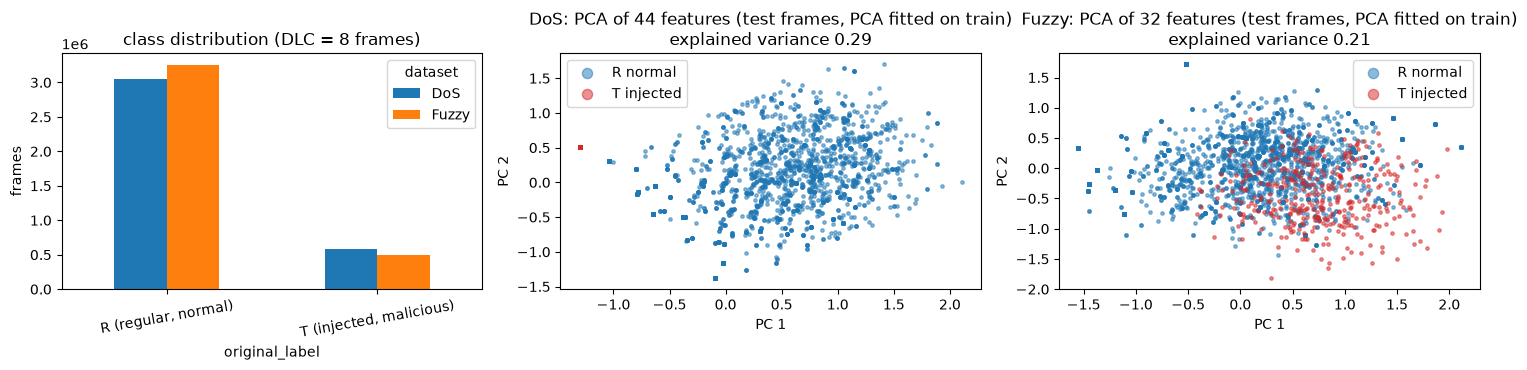

In [7]:
def feature_names(name, mode="paper"):
    P = PREP[name]
    idn = [f"ID=0x{i:03x}" for i in P["ids"]] if name == "DoS" else [f"ID_bit{k}" for k in range(P["nb_c"])]
    return ["Frequency_ms"] + idn + [f"payload_bit{k}" for k in range(P["nb_d"])]

# ---- shape, feature names, original labels, class counts ----
shape_rows, count_rows = [], []
for name in ["DoS", "Fuzzy"]:
    P = PREP[name]; fn = feature_names(name)
    shape_rows.append(dict(dataset=name, frames=len(P["y"]), n_features=len(fn), first_features=", ".join(fn[:3]) + ", ... , " + fn[-1]))
    for lab, txt in [(0, "R (regular, normal)"), (1, "T (injected, malicious)")]:
        count_rows.append(dict(dataset=name, original_label=txt, frames=int((P["y"] == lab).sum()), share=round(float((P["y"] == lab).mean()), 4)))
display(pd.DataFrame(shape_rows)); display(pd.DataFrame(count_rows))
print("feature names, DoS   :", feature_names("DoS"))
print("feature names, Fuzzy :", feature_names("Fuzzy"))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cnt = pd.DataFrame(count_rows).pivot(index="original_label", columns="dataset", values="frames")
cnt.plot.bar(ax=ax[0], rot=10, color=["tab:blue", "tab:orange"]); ax[0].set_title("class distribution (DLC = 8 frames)"); ax[0].set_ylabel("frames")
for a, name in zip(ax[1:], ["DoS", "Fuzzy"]):
    Xa, Xb, ya, yb = make_round(name, N_TOTAL, SEED)
    pca = PCA(n_components=2, random_state=SEED).fit(Xa)           # fitted on the training split only
    Z = pca.transform(Xb); sel = np.random.default_rng(SEED).choice(len(Z), size=min(3000, len(Z)), replace=False)
    for lab, col, txt in [(0, "tab:blue", "R normal"), (1, "tab:red", "T injected")]:
        m = sel[yb[sel] == lab]; a.scatter(Z[m, 0], Z[m, 1], s=6, alpha=.5, c=col, label=txt)
    a.set_title(f"{name}: PCA of {Xb.shape[1]} features (test frames, PCA fitted on train)\nexplained variance {pca.explained_variance_ratio_.sum():.2f}")
    a.set_xlabel("PC 1"); a.set_ylabel("PC 2"); a.legend(markerscale=3)
plt.tight_layout(); plt.show()

In the DoS plot every injected frame has the same feature vector (ID `0000`, empty payload, tiny Frequency), so all of them land on **one single point** (the red dot at the far left, drawn on top of one another); the normal frames form a cloud elsewhere. That is why almost any classifier is perfect on DoS. The Fuzzy frames are spread out and overlap the normal ones in two dimensions (random IDs and payloads), although the injected ones lean towards one side; a classifier has to use many of the bit features. Two components explain only 21 to 29 % of the variance, so this picture is an illustration, not a separability proof.

## 4. QBoost as a QUBO

**Weak classifiers.** A pool of `K` classifiers `h_i(x)` with output -1 (malicious) or +1 (normal). Here: shallow decision trees,
each trained on a small random subset of the training frames and a random subset of features (`# CHOICE`).

**Strong classifier.** `H(x) = sign( (1/K) * sum_i w_i * h_i(x) )`, with binary weights `w_i`.

**Objective** (Neven et al.): over the training frames `s = 1..S` with labels `y_s in {-1, +1}`

`min_w  (1/S) * sum_s ( (1/K) * sum_i w_i * h_i(x_s) - y_s )^2  +  lambda * sum_i w_i`

Because `w_i` is binary, `w_i^2 = w_i`, and the objective is a quadratic function of the bits `w_i`:

* diagonal: `Q_ii = (1/(S K^2)) * sum_s h_i(x_s)^2  -  (2/(S K)) * sum_s h_i(x_s) y_s  +  lambda`
* off-diagonal: `Q_ij = (2/(S K^2)) * sum_s h_i(x_s) h_j(x_s)`  for `i < j`

That matrix is the QUBO an annealer minimises. The code below builds it, solves it with simulated annealing
(`SA_READS` independent runs of `SA_SWEEPS` sweeps) and, as a check, compares simulated annealing with **exhaustive
enumeration** on a 16-variable QUBO taken from a real weak-classifier pool.

In [8]:
def qubo_matrix(H, ypm, lam):
    """Upper-triangular QUBO matrix of the QBoost objective; H is (S, K) with entries in {-1, +1}, ypm in {-1, +1}."""
    S, K = H.shape
    G = (H.T @ H) / (S * K * K)
    lin = -2.0 * (H.T @ ypm) / (S * K) + lam
    Q = np.triu(2.0 * G, 1)
    np.fill_diagonal(Q, np.diag(G) + lin)
    return Q

def solve_qubo(Q, reads, seed):
    """CHOICE: classical simulated annealing instead of the D-Wave Leap hybrid solver."""
    bqm = dimod.BinaryQuadraticModel(Q, "BINARY")
    ss = SimulatedAnnealingSampler().sample(bqm, num_reads=reads, num_sweeps=SA_SWEEPS, seed=seed)
    best = ss.first
    return np.array([best.sample[i] for i in range(Q.shape[0])], dtype=float), float(best.energy)

def tree_pool(Xtr, ytr, K, depth, seed):
    r = np.random.default_rng(seed); trees = []
    for k in range(K):
        b = r.choice(len(ytr), size=min(TREE_ROWS, len(ytr)), replace=False)
        trees.append(DecisionTreeClassifier(max_depth=depth, max_features="sqrt", random_state=seed + k).fit(Xtr[b], ytr[b]))
    return trees

def pool_outputs(trees, X):
    """(n, K) matrix of weak votes: +1 = normal, -1 = malicious (attack label 1 -> -1).
    Same result as tree.predict, but calls the tree's leaf lookup directly (no input validation per tree), which is much faster."""
    Xf = np.ascontiguousarray(X, dtype=np.float32)
    out = np.empty((len(Xf), len(trees)))
    for k, t in enumerate(trees):
        leaf_is_attack = t.tree_.value[:, 0, :].argmax(1) == t.classes_.tolist().index(1) if 1 in t.classes_ else np.zeros(t.tree_.node_count, bool)
        out[:, k] = np.where(leaf_is_attack[t.tree_.apply(Xf)], -1.0, 1.0)
    return out

class QBoost:
    def __init__(self, K=K_POOL, depth=TREE_DEPTH, lambdas=LAMBDAS, reads=SA_READS, seed=SEED):
        self.K, self.depth, self.lambdas, self.reads, self.seed = K, depth, lambdas, reads, seed
    def fit(self, X, y):
        t0 = time.time(); ypm = np.where(y == 0, 1.0, -1.0)
        self.trees = tree_pool(X, y, self.K, self.depth, self.seed)
        H = pool_outputs(self.trees, X); self.t_pool = time.time() - t0
        # lambda chosen on a validation part of the training data (never on the test set)
        r = np.random.default_rng(self.seed); idx = r.permutation(len(y)); nv = int(VAL_FRAC * len(y)); va, tr = idx[:nv], idx[nv:]
        self.scan = []; best = None; t_sa = 0.0
        for lam in self.lambdas:
            Q = qubo_matrix(H[tr], ypm[tr], lam); t1 = time.time()
            w, e = solve_qubo(Q, self.reads, self.seed); t_sa += time.time() - t1
            s = H[va] @ w; pv = np.where(s >= 0, 1.0, -1.0) if w.sum() > 0 else np.ones(len(va))
            acc = float((pv == ypm[va]).mean()); self.scan.append((lam, int(w.sum()), acc))
            if best is None or acc > best[0]: best = (acc, lam)
        self.lam = best[1]
        t1 = time.time(); self.w, self.energy = solve_qubo(qubo_matrix(H, ypm, self.lam), self.reads, self.seed); t_sa += time.time() - t1
        self.selected = [t for t, wi in zip(self.trees, self.w) if wi > 0]
        self.t_sa = t_sa; self.t_fit = time.time() - t0
        return self
    def predict(self, X):
        if not self.selected: return np.zeros(len(X), dtype=int)
        s = pool_outputs(self.selected, X).sum(1)
        return (s < 0).astype(int)                      # 1 = malicious; ties -> normal (sign(0) := +1)

# ---- check: simulated annealing vs exhaustive enumeration on a 16-variable QUBO built from real weak classifiers ----
Xs, _, ys, _ = make_round("Fuzzy", 10_000, SEED)
trees16 = tree_pool(Xs, ys, 16, TREE_DEPTH, SEED)
ypm_s = np.where(ys == 0, 1.0, -1.0)
H16 = pool_outputs(trees16, Xs)
assert np.array_equal(H16, np.stack([np.where(t.predict(Xs) == 1, -1.0, 1.0) for t in trees16], axis=1)), "fast vote lookup must equal tree.predict"
Q16 = qubo_matrix(H16, ypm_s, 3e-3)
t0 = time.time(); exact = dimod.ExactSolver().sample(dimod.BinaryQuadraticModel(Q16, "BINARY")).first; t_exact = time.time() - t0
w_sa, e_sa = solve_qubo(Q16, SA_READS, SEED)
print(f"exhaustive minimum energy over 2^16 assignments: {exact.energy:.8f}  ({t_exact:.1f} s)")
print(f"simulated annealing ({SA_READS} reads):             {e_sa:.8f}")
print("same optimum found:", bool(np.isclose(exact.energy, e_sa)), "| weights equal:", bool(np.array_equal([exact.sample[i] for i in range(16)], w_sa)))

exhaustive minimum energy over 2^16 assignments: -0.92349023  (0.3 s)
simulated annealing (50 reads):             -0.92349023
same optimum found: True | weights equal: True


If the two energies agree, simulated annealing finds the optimum of a QUBO of exactly the kind the paper sends to D-Wave, so
the classical stand-in is a fair substitute for *solution quality* on problems this small. (The real annealer has no
guarantee either; for the 60 to 100 variables used below nothing can be enumerated, so we rely on many annealing reads.)

## 5. Training and evaluating the classifiers

Per round and per attack file: **SVC** (paper), **QBoost** (paper, depth-3 trees), **QBoost-stumps** (depth-1 trees, Neven's
original weak learners; ablation), and two classical baselines on the identical inputs, **RandomForest** and **AdaBoost**.
Metrics are computed with *normal as the positive class* (the paper's convention: its Fig. 2 labels `0 = malicious`,
`1 = normal`) and additionally with *attack as the positive class*. Timing = wall-clock `fit` and `predict` on this CPU.

In [9]:
def pos_normal(y_attack): return 1 - np.asarray(y_attack)

def score(y_true, y_pred):
    yn, pn = pos_normal(y_true), pos_normal(y_pred)
    return dict(acc=accuracy_score(yn, pn), prec=precision_score(yn, pn, zero_division=0), rec=recall_score(yn, pn, zero_division=0),
                f1=f1_score(yn, pn, zero_division=0),
                atk_rec=recall_score(y_true, y_pred, zero_division=0), atk_f1=f1_score(y_true, y_pred, zero_division=0))

def make_models(seed):
    return {"SVC": SVC(),                                                       # CHOICE: sklearn defaults (RBF, C=1)
            "QBoost": QBoost(depth=TREE_DEPTH, seed=seed),
            "QBoost-stumps": QBoost(depth=1, seed=seed),
            "RandomForest": RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=-1),
            "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=seed)}

RES, CMS, QB_LOG = [], {}, {}
def run_round(name, rnd, mode="paper", models=None):
    seed = SEED + rnd
    Xtr, Xte, ytr, yte = make_round(name, N_TOTAL, seed, mode)
    for mname, m in make_models(seed).items():
        if models and mname not in models: continue
        t0 = time.time(); m.fit(Xtr, ytr); t_fit = time.time() - t0
        t0 = time.time(); pte = m.predict(Xte); t_pred = time.time() - t0
        ptr = m.predict(Xtr)
        row = dict(dataset=name, mode=mode, round=rnd, model=mname, fit_s=t_fit, pred_s=t_pred, n_features=Xtr.shape[1])
        row.update({f"test_{k}": v for k, v in score(yte, pte).items()}); row.update({f"train_{k}": v for k, v in score(ytr, ptr).items()})
        if isinstance(m, QBoost):
            row.update(lam=m.lam, n_selected=len(m.selected), t_pool=m.t_pool, t_sa=m.t_sa)
            QB_LOG[(name, mode, rnd, mname)] = m.scan
        RES.append(row)
        CMS[(name, mode, rnd, mname)] = confusion_matrix(pos_normal(yte), pos_normal(pte), labels=[0, 1])

t_all = time.time()
for name in ["DoS", "Fuzzy"]:
    for rnd in range(ROUNDS):
        run_round(name, rnd, "paper")
        print(f"{name} round {rnd + 1}/{ROUNDS} done ({time.time() - t_all:.0f} s elapsed)", flush=True)
RESDF = pd.DataFrame(RES)
print("main experiment finished in %.1f min" % ((time.time() - t_all) / 60))

DoS round 1/10 done (98 s elapsed)


DoS round 2/10 done (141 s elapsed)


DoS round 3/10 done (168 s elapsed)


DoS round 4/10 done (193 s elapsed)


DoS round 5/10 done (265 s elapsed)


...

Fuzzy round 7/10 done (1035 s elapsed)


Fuzzy round 8/10 done (1179 s elapsed)


Fuzzy round 9/10 done (1257 s elapsed)


Fuzzy round 10/10 done (1361 s elapsed)


main experiment finished in 22.7 min


### 5.1 Test-set metrics (mean +- std over the rounds)

In [10]:
def summary(df, split="test", cols=("acc", "prec", "rec", "f1")):
    out = []
    for (d, m), g in df.groupby(["dataset", "model"], sort=False):
        row = dict(dataset=d, model=m)
        for c in cols:
            v = g[f"{split}_{c}"]; row[c] = f"{v.mean():.4f} +- {v.std(ddof=0):.4f}"
        row["fit_s"] = f"{g.fit_s.mean():.2f}"; row["predict_s"] = f"{g.pred_s.mean():.3f}"
        out.append(row)
    return pd.DataFrame(out)

main = RESDF[RESDF["mode"] == "paper"]
print("TEST set, normal = positive class (paper's convention), %d rounds of %d frames:" % (ROUNDS, N_TOTAL))
display(summary(main, "test"))
print("TRAIN set:")
display(summary(main, "train"))
print("TEST set, attack = positive class:")
display(summary(main, "test", ("atk_rec", "atk_f1")))

TEST set, normal = positive class (paper's convention), 10 rounds of 50000 frames:


,dataset,model,acc,prec,rec,f1,fit_s,predict_s
0,DoS,SVC,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,0.59,0.125
1,DoS,QBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,22.59,0.101
2,DoS,QBoost-stumps,0.9852 +- 0.0014,0.9850 +- 0.0009,0.9976 +- 0.0013,0.9912 +- 0.0008,24.85,0.034
3,DoS,RandomForest,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.32,0.191
4,DoS,AdaBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,0.15,0.008
5,Fuzzy,SVC,0.9979 +- 0.0002,0.9977 +- 0.0003,0.9998 +- 0.0001,0.9988 +- 0.0001,9.97,3.078
6,Fuzzy,QBoost,0.9962 +- 0.0005,0.9959 +- 0.0006,0.9997 +- 0.0002,0.9978 +- 0.0003,23.25,0.079
7,Fuzzy,QBoost-stumps,0.9861 +- 0.0019,0.9844 +- 0.0022,0.9999 +- 0.0001,0.9921 +- 0.0011,19.63,0.035
8,Fuzzy,RandomForest,0.9982 +- 0.0003,0.9981 +- 0.0003,0.9998 +- 0.0001,0.9989 +- 0.0002,2.18,0.164
9,Fuzzy,AdaBoost,0.9965 +- 0.0005,0.9970 +- 0.0005,0.9990 +- 0.0005,0.9980 +- 0.0003,10.35,0.426


TRAIN set:


,dataset,model,acc,prec,rec,f1,fit_s,predict_s
0,DoS,SVC,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,0.59,0.125
1,DoS,QBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,22.59,0.101
2,DoS,QBoost-stumps,0.9857 +- 0.0013,0.9855 +- 0.0007,0.9976 +- 0.0012,0.9915 +- 0.0008,24.85,0.034
3,DoS,RandomForest,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.32,0.191
4,DoS,AdaBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,0.15,0.008
5,Fuzzy,SVC,0.9985 +- 0.0002,0.9984 +- 0.0002,0.9999 +- 0.0000,0.9992 +- 0.0001,9.97,3.078
6,Fuzzy,QBoost,0.9965 +- 0.0003,0.9963 +- 0.0003,0.9997 +- 0.0002,0.9980 +- 0.0002,23.25,0.079
7,Fuzzy,QBoost-stumps,0.9866 +- 0.0019,0.9849 +- 0.0021,0.9999 +- 0.0000,0.9923 +- 0.0011,19.63,0.035
8,Fuzzy,RandomForest,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,2.18,0.164
9,Fuzzy,AdaBoost,0.9966 +- 0.0004,0.9972 +- 0.0003,0.9989 +- 0.0003,0.9981 +- 0.0002,10.35,0.426


TEST set, attack = positive class:


,dataset,model,atk_rec,atk_f1,fit_s,predict_s
0,DoS,SVC,1.0000 +- 0.0000,1.0000 +- 0.0000,0.59,0.125
1,DoS,QBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,22.59,0.101
2,DoS,QBoost-stumps,0.9215 +- 0.0048,0.9530 +- 0.0042,24.85,0.034
3,DoS,RandomForest,1.0000 +- 0.0000,1.0000 +- 0.0000,1.32,0.191
4,DoS,AdaBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,0.15,0.008
5,Fuzzy,SVC,0.9849 +- 0.0018,0.9918 +- 0.0010,9.97,3.078
6,Fuzzy,QBoost,0.9730 +- 0.0038,0.9854 +- 0.0020,23.25,0.079
7,Fuzzy,QBoost-stumps,0.8949 +- 0.0152,0.9441 +- 0.0085,19.63,0.035
8,Fuzzy,RandomForest,0.9871 +- 0.0019,0.9930 +- 0.0011,2.18,0.164
9,Fuzzy,AdaBoost,0.9801 +- 0.0030,0.9865 +- 0.0020,10.35,0.426


### 5.2 Confusion matrices (paper's Fig. 2 layout, last round)

`0` = malicious, `1` = normal; the cells are TN / FP / FN / TP with *normal* as the positive class, as in the paper.

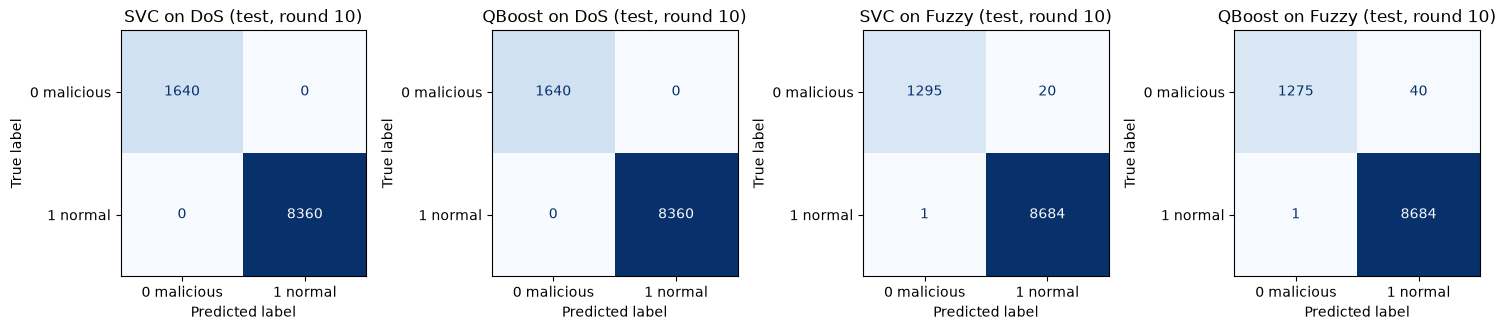

In [11]:
last = ROUNDS - 1
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, (name, m) in zip(ax, [("DoS", "SVC"), ("DoS", "QBoost"), ("Fuzzy", "SVC"), ("Fuzzy", "QBoost")]):
    ConfusionMatrixDisplay(CMS[(name, "paper", last, m)], display_labels=["0 malicious", "1 normal"]).plot(ax=a, colorbar=False, values_format="d", cmap="Blues")
    a.set_title(f"{m} on {name} (test, round {last + 1})")
plt.tight_layout(); plt.show()

### 5.3 What QBoost selected, and how lambda was chosen

Each point is one annealing problem: a larger `lambda` penalises every selected classifier, so fewer are kept. The
validation accuracy (never the test set) picks `lambda`.

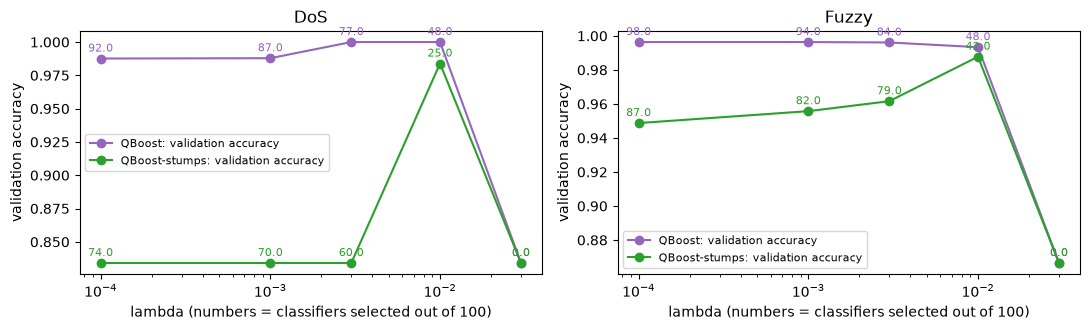

            lam                n_selected            
           mean     min    max       mean   min   max
dataset                                              
DoS      0.0022  0.0001  0.003       81.0  76.0  92.0
Fuzzy    0.0008  0.0001  0.003       95.0  84.0  99.0


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, name in zip(ax, ["DoS", "Fuzzy"]):
    for mname, col in [("QBoost", "tab:purple"), ("QBoost-stumps", "tab:green")]:
        sc = np.array(QB_LOG[(name, "paper", last, mname)])
        a.plot(sc[:, 0], sc[:, 2], "o-", color=col, label=f"{mname}: validation accuracy")
        for lam, k, acc in sc: a.annotate(str(k), (lam, acc), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8, color=col)
    a.set_xscale("log"); a.set_xlabel("lambda (numbers = classifiers selected out of %d)" % K_POOL); a.set_ylabel("validation accuracy"); a.set_title(name); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(main[main.model == "QBoost"].groupby("dataset")[["lam", "n_selected"]].agg(["mean", "min", "max"]).round(4))

## 6. Timing: the paper's Tables 1 and 2

The paper's claim is about **time**: QBoost trains and predicts much faster than SVC. Two things make a literal comparison
impossible here: (a) the paper timed a D-Wave cloud solve, we time a local simulated-annealing run, and (b) the paper's SVC
was trained on about 2.9 to 3.0 million frames, ours on the sample above. So there are three views: the timing of the main
experiment, a **scaling study** (training-set size vs time, for SVC and QBoost) and a **power-law extrapolation** of both to the
paper's data size. Extrapolation is an estimate, not a measurement.

In [13]:
tab = []
for name in ["DoS", "Fuzzy"]:
    g = main[main.dataset == name]
    s, q = g[g.model == "SVC"], g[g.model == "QBoost"]
    for what, a, b in [("training time (s)", s.fit_s.mean(), q.fit_s.mean()), ("prediction time (s)", s.pred_s.mean(), q.pred_s.mean())]:
        tab.append(dict(dataset=name, quantity=what, SVC=round(a, 4), QBoost=round(b, 4), difference=round(b - a, 4), gain_pct=round(100 * (a - b) / a, 1)))
display(pd.DataFrame(tab))
print("time split of QBoost training (mean over rounds, seconds):")
display(main[main.model == "QBoost"].groupby("dataset")[["fit_s", "t_pool", "t_sa"]].mean().round(2).rename(columns={"fit_s": "total fit", "t_pool": "weak-classifier pool + votes", "t_sa": "all annealing runs (lambda scan + final)"}))

,dataset,quantity,SVC,QBoost,difference,gain_pct
0,DoS,training time (s),0.5921,22.5877,21.9956,-3714.8
1,DoS,prediction time (s),0.1248,0.1010,-0.0237,19.0
2,Fuzzy,training time (s),9.9701,23.2543,13.2843,-133.2
3,Fuzzy,prediction time (s),3.0776,0.0794,-2.9982,97.4


time split of QBoost training (mean over rounds, seconds):


,total fit,weak-classifier pool + votes,all annealing runs (lambda scan + final)
dataset,,,
DoS,22.59,1.76,7.99
Fuzzy,23.25,1.42,8.70


DoS n_train=  2500: SVC fit 0.02s pred 0.044s acc 1.0000 | QBoost fit 6.93s pred 0.034s acc 1.0000


DoS n_train=  5000: SVC fit 0.04s pred 0.040s acc 1.0000 | QBoost fit 7.52s pred 0.036s acc 1.0000


DoS n_train= 10000: SVC fit 0.10s pred 0.048s acc 1.0000 | QBoost fit 20.23s pred 0.018s acc 1.0000


DoS n_train= 20000: SVC fit 0.22s pred 0.038s acc 1.0000 | QBoost fit 34.54s pred 0.040s acc 1.0000


DoS n_train= 40000: SVC fit 0.47s pred 0.036s acc 1.0000 | QBoost fit 34.55s pred 0.052s acc 1.0000


...

Fuzzy n_train=  5000: SVC fit 0.32s pred 0.384s acc 0.9960 | QBoost fit 9.89s pred 0.037s acc 0.9942


Fuzzy n_train= 10000: SVC fit 0.92s pred 0.599s acc 0.9976 | QBoost fit 14.24s pred 0.058s acc 0.9964


Fuzzy n_train= 20000: SVC fit 4.45s pred 1.220s acc 0.9976 | QBoost fit 6.82s pred 0.035s acc 0.9958


Fuzzy n_train= 40000: SVC fit 14.35s pred 1.203s acc 0.9976 | QBoost fit 10.87s pred 0.042s acc 0.9966


scaling study finished in 3.0 min


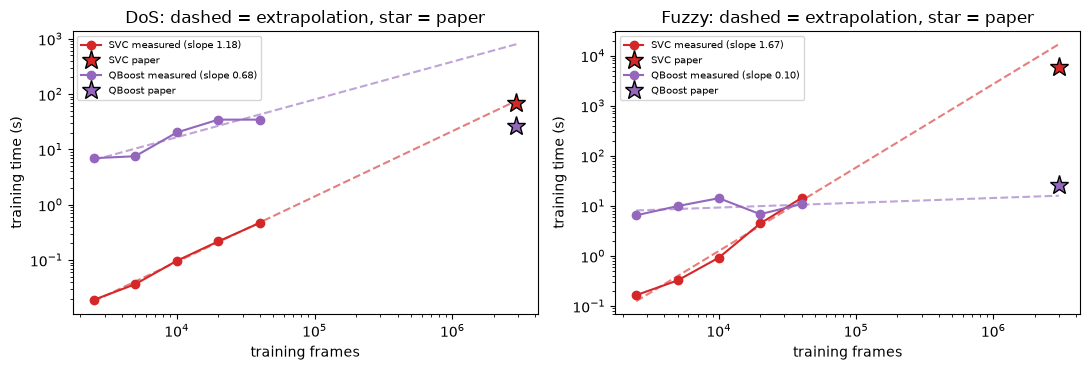

,dataset,model,slope,extrapolated_train_s,extrapolated_predict_s,paper_train_s,paper_predict_s
0,DoS,SVC,1.18,75.7,4.01,68.6735,2.5609
1,DoS,QBoost,0.68,800.2,10.52,26.1415,0.0275
2,Fuzzy,SVC,1.67,16900.3,973.01,5933.2840,431.4609
3,Fuzzy,QBoost,0.10,16.0,8.83,25.7134,0.1462


In [14]:
# ---- scaling study: training time vs number of training frames (one seed per size, same pool of frames) ----
SCALE = []
t_all = time.time()
for name in ["DoS", "Fuzzy"]:
    P = PREP[name]
    for n in SCALE_SIZES:
        r = np.random.default_rng(SEED + n)
        pick = r.choice(len(P["y"]), size=n + N_PRED_TIME, replace=False)
        tr, te = pick[:n], pick[n:]
        Xa, Xb = design_matrix(P, tr, te, "paper"); sc = MinMaxScaler().fit(Xa); Xa, Xb = sc.transform(Xa), np.clip(sc.transform(Xb), 0, 1)
        ya, yb = P["y"][tr], P["y"][te]
        for mname, m in [("SVC", SVC()), ("QBoost", QBoost(depth=TREE_DEPTH, seed=SEED))]:
            t0 = time.time(); m.fit(Xa, ya); tf = time.time() - t0
            t0 = time.time(); p = m.predict(Xb); tp = time.time() - t0
            SCALE.append(dict(dataset=name, n_train=n, model=mname, fit_s=tf, pred_s=tp, test_acc=accuracy_score(yb, p)))
        print(f"{name} n_train={n:>6}: " + " | ".join(f"{d['model']} fit {d['fit_s']:.2f}s pred {d['pred_s']:.3f}s acc {d['test_acc']:.4f}" for d in SCALE[-2:]), flush=True)
SCDF = pd.DataFrame(SCALE)
print("scaling study finished in %.1f min" % ((time.time() - t_all) / 60))

# power-law fit  t = a * n^b  on the log-log data, extrapolated to the paper's training-set size (80 % of the DLC-8 frames)
N_PAPER_TRAIN = {n: int(0.8 * len(PREP[n]["y"])) for n in PREP}
EXTRA = {}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, name in zip(ax, ["DoS", "Fuzzy"]):
    for mname, col in [("SVC", "tab:red"), ("QBoost", "tab:purple")]:
        g = SCDF[(SCDF.dataset == name) & (SCDF.model == mname)]
        b, la = np.polyfit(np.log(g.n_train), np.log(g.fit_s), 1)
        bp, lap = np.polyfit(np.log(g.n_train), np.log(g.pred_s), 1)
        # prediction time: power law in n_train (fixed 5,000-frame test set), then scaled linearly to the paper's test-set size
        n_test_paper = len(PREP[name]["y"]) - N_PAPER_TRAIN[name]
        EXTRA[(name, mname)] = (float(np.exp(la) * N_PAPER_TRAIN[name] ** b),
                                float(np.exp(lap) * N_PAPER_TRAIN[name] ** bp * n_test_paper / N_PRED_TIME), b)
        a.loglog(g.n_train, g.fit_s, "o-", color=col, label=f"{mname} measured (slope {b:.2f})")
        xs = np.array([g.n_train.min(), N_PAPER_TRAIN[name]]); a.loglog(xs, np.exp(la) * xs ** b, "--", color=col, alpha=.6)
        a.plot([N_PAPER_TRAIN[name]], [PAPER_TIME[name][mname][0]], "*", color=col, ms=14, mec="k", label=f"{mname} paper")
    a.set_xlabel("training frames"); a.set_ylabel("training time (s)"); a.set_title(f"{name}: dashed = extrapolation, star = paper"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
ex = pd.DataFrame([dict(dataset=n, model=m, slope=round(v[2], 2), extrapolated_train_s=round(v[0], 1), extrapolated_predict_s=round(v[1], 2),
                        paper_train_s=PAPER_TIME[n][m][0], paper_predict_s=PAPER_TIME[n][m][1]) for (n, m), v in EXTRA.items()])
display(ex)

Reading the plot: the slope on log-log axes is the exponent of the cost. SVC with an RBF kernel is typically between linear
and quadratic in the number of frames (and much worse on hard data such as Fuzzy, where almost every frame becomes a
support vector); QBoost in this implementation is dominated by evaluating the weak classifiers on every training frame
(linear, small constant) plus an annealing time that does **not** depend on the number of frames (it depends on the number of
weak classifiers `K`). That is the mechanism behind the paper's claim, and the extrapolation shows how far it carries.
A real D-Wave hybrid-solver call has its own fixed minimum run time and network latency, which a local annealer does not have.

## 7. Robustness: the leakage-free (`strict`) encoding

Same experiment, but the ID / payload codes are fitted on the training frames only. A payload never seen in training gets one
reserved code. This takes away the (label-free) information that "this payload string first appears late in the log".

In [15]:
t_all = time.time()
for name in ["DoS", "Fuzzy"]:
    for rnd in range(STRICT_ROUNDS):
        run_round(name, rnd, "strict", models=["SVC", "QBoost", "RandomForest"])
RESDF = pd.DataFrame(RES)
strict = RESDF[RESDF["mode"] == "strict"]
print("strict encoding, test set, normal = positive class (%d rounds):" % STRICT_ROUNDS)
display(summary(strict, "test"))
print("same rounds with the paper-style encoding, for comparison:")
display(summary(RESDF[(RESDF["mode"] == "paper") & (RESDF["round"] < STRICT_ROUNDS) & RESDF.model.isin(["SVC", "QBoost", "RandomForest"])], "test"))
print("strict variant finished in %.1f min" % ((time.time() - t_all) / 60))

strict encoding, test set, normal = positive class (3 rounds):


,dataset,model,acc,prec,rec,f1,fit_s,predict_s
0,DoS,SVC,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,0.58,0.097
1,DoS,QBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,21.29,0.103
2,DoS,RandomForest,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.05,0.112
3,Fuzzy,SVC,0.9976 +- 0.0002,0.9975 +- 0.0002,0.9997 +- 0.0002,0.9986 +- 0.0001,14.75,3.436
4,Fuzzy,QBoost,0.9947 +- 0.0003,0.9962 +- 0.0004,0.9977 +- 0.0004,0.9970 +- 0.0002,26.74,0.102
5,Fuzzy,RandomForest,0.9979 +- 0.0000,0.9981 +- 0.0001,0.9995 +- 0.0002,0.9988 +- 0.0000,2.57,0.229


same rounds with the paper-style encoding, for comparison:


,dataset,model,acc,prec,rec,f1,fit_s,predict_s
0,DoS,SVC,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,0.67,0.122
1,DoS,QBoost,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,25.43,0.092
2,DoS,RandomForest,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.47,0.122
3,Fuzzy,SVC,0.9979 +- 0.0002,0.9978 +- 0.0003,0.9998 +- 0.0001,0.9988 +- 0.0001,11.08,2.858
4,Fuzzy,QBoost,0.9964 +- 0.0004,0.9960 +- 0.0006,0.9998 +- 0.0001,0.9979 +- 0.0002,19.50,0.082
5,Fuzzy,RandomForest,0.9980 +- 0.0003,0.9980 +- 0.0003,0.9997 +- 0.0001,0.9988 +- 0.0002,2.22,0.242


strict variant finished in 4.5 min


## 8. Side by side with the paper

Verdict rule for accuracy, precision, recall and F1: **reproduced** if within 0.02 of the paper's value, **exceeded** if
better by more than 0.02, **not reached** if worse by more than 0.02. Timing claims are compared as the relative gain
`(SVC - QBoost) / SVC`.

In [16]:
def verdict(ours, paper, tol=0.02):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded (+%.3f)" % d if d > 0 else "not reached (%.3f)" % d)

# ---------- Table 3 analogue ----------
rows = []
for (d, split, clf), pv in PAPER_T3.items():
    g = main[(main.dataset == d) & (main.model == clf)]
    s = split.lower()
    ours = [g[f"{s}_{k}"].mean() for k in ["acc", "prec", "rec", "f1"]]
    for k, o, p in zip(["accuracy", "precision", "recall", "F1"], ours, pv):
        rows.append(dict(claim=f"{d} {split} {clf} {k}", paper=p, notebook=round(o, 4), verdict=verdict(o, p)))
T3 = pd.DataFrame(rows)
display(T3)
print("verdict counts (Table 3):", T3.verdict.str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook,verdict
0,DoS Train SVC accuracy,1.0000,1.0000,reproduced
1,DoS Train SVC precision,1.0000,1.0000,reproduced
2,DoS Train SVC recall,1.0000,1.0000,reproduced
3,DoS Train SVC F1,1.0000,1.0000,reproduced
4,DoS Train QBoost accuracy,1.0000,1.0000,reproduced
5,DoS Train QBoost precision,1.0000,1.0000,reproduced
6,DoS Train QBoost recall,1.0000,1.0000,reproduced
7,DoS Train QBoost F1,1.0000,1.0000,reproduced
8,DoS Test SVC accuracy,1.0000,1.0000,reproduced
9,DoS Test SVC precision,1.0000,1.0000,reproduced


verdict counts (Table 3): {'reproduced': 28, 'exceeded': 4}


In [17]:
claims = []
# DoS perfect in every round?
g = main[(main.dataset == "DoS") & main.model.isin(["SVC", "QBoost"])]
perfect = bool((g[["test_acc", "test_prec", "test_rec", "test_f1"]] == 1.0).all().all())
claims.append(("DoS: SVC and QBoost both 1.0 on the test set in every round", "1.0", "all rounds = 1.0" if perfect else "min acc %.4f" % g.test_acc.min(),
               "reproduced" if perfect else "not reached"))
# recall ordering on Fuzzy
gf = main[main.dataset == "Fuzzy"]
r_s, r_q = gf[gf.model == "SVC"].test_rec.mean(), gf[gf.model == "QBoost"].test_rec.mean()
claims.append(("Fuzzy: SVC recall slightly better than QBoost", "0.9892 vs 0.9760", "%.4f vs %.4f" % (r_s, r_q),
               "reproduced" if r_s > r_q else "not reached (QBoost recall >= SVC here)"))
# QBoost similar accuracy to SVC (within 1 point)
for d in ["DoS", "Fuzzy"]:
    a_s, a_q = main[(main.dataset == d) & (main.model == "SVC")].test_acc.mean(), main[(main.dataset == d) & (main.model == "QBoost")].test_acc.mean()
    claims.append((f"{d}: QBoost accuracy within 1 point of SVC", "similar", "SVC %.4f, QBoost %.4f" % (a_s, a_q), "reproduced" if abs(a_s - a_q) <= 0.01 else "not reached"))
# feature counts
for d in ["DoS", "Fuzzy"]:
    claims.append((f"{d}: number of features", str(PAPER_FEATURES[d]), str(PREP[d]["n_features_paper_style"]), "reproduced" if PREP[d]["n_features_paper_style"] == PAPER_FEATURES[d] else "off by %d" % (PREP[d]["n_features_paper_style"] - PAPER_FEATURES[d])))
# timing claims: measured at the main-experiment size, at the largest scaling size, and extrapolated
PAPER_GAIN = {d: tuple(100 * (PAPER_TIME[d]["SVC"][i] - PAPER_TIME[d]["QBoost"][i]) / PAPER_TIME[d]["SVC"][i] for i in (0, 1)) for d in PAPER_TIME}
def gain(a, b): return 100 * (a - b) / a
def tverdict(g_ours, g_paper):
    if g_ours < 0: return "not reached (QBoost slower)"
    return "reproduced" if abs(g_ours - g_paper) <= 10 else ("exceeded" if g_ours > g_paper else "not reached")
for d in ["DoS", "Fuzzy"]:
    for i, what in enumerate(["training", "prediction"]):
        nmax = SCDF[SCDF.dataset == d].n_train.max()
        s = SCDF[(SCDF.dataset == d) & (SCDF.n_train == nmax) & (SCDF.model == "SVC")].iloc[0]; q = SCDF[(SCDF.dataset == d) & (SCDF.n_train == nmax) & (SCDF.model == "QBoost")].iloc[0]
        gm = gain(s.fit_s if i == 0 else s.pred_s, q.fit_s if i == 0 else q.pred_s)
        claims.append((f"{d}: {what}-time gain of QBoost, measured at n_train={nmax}", "%.1f %%" % PAPER_GAIN[d][i], "%.1f %%" % gm, tverdict(gm, PAPER_GAIN[d][i])))
        ge = gain(EXTRA[(d, "SVC")][i], EXTRA[(d, "QBoost")][i])
        claims.append((f"{d}: {what}-time gain, power-law EXTRAPOLATION to n_train={N_PAPER_TRAIN[d]:,}", "%.1f %%" % PAPER_GAIN[d][i], "%.1f %%" % ge,
                       tverdict(ge, PAPER_GAIN[d][i]) + " [extrapolated, cannot be checked directly]"))
claims.append(("QBoost on a real D-Wave Leap hybrid solver", "26.1 s / 25.7 s training", "simulated annealing on CPU (no annealer used)", "cannot be checked"))
CLAIMS = pd.DataFrame(claims, columns=["claim", "paper", "notebook", "verdict"])
pd.set_option("display.max_colwidth", 110)
display(CLAIMS)

,claim,paper,notebook,verdict
0,DoS: SVC and QBoost both 1.0 on the test set in every round,1.0,all rounds = 1.0,reproduced
1,Fuzzy: SVC recall slightly better than QBoost,0.9892 vs 0.9760,0.9998 vs 0.9997,reproduced
2,DoS: QBoost accuracy within 1 point of SVC,similar,"SVC 1.0000, QBoost 1.0000",reproduced
3,Fuzzy: QBoost accuracy within 1 point of SVC,similar,"SVC 0.9979, QBoost 0.9962",reproduced
4,DoS: number of features,43,44,off by 1
5,Fuzzy: number of features,32,32,reproduced
6,"DoS: training-time gain of QBoost, measured at n_train=40000",61.9 %,-7276.9 %,not reached (QBoost slower)
7,"DoS: training-time gain, power-law EXTRAPOLATION to n_train=2,907,666",61.9 %,-957.4 %,"not reached (QBoost slower) [extrapolated, cannot be checked directly]"
8,"DoS: prediction-time gain of QBoost, measured at n_train=40000",98.9 %,-45.7 %,not reached (QBoost slower)
9,"DoS: prediction-time gain, power-law EXTRAPOLATION to n_train=2,907,666",98.9 %,-162.2 %,"not reached (QBoost slower) [extrapolated, cannot be checked directly]"


In [18]:
print("=" * 100); print("PAPER vs THIS NOTEBOOK: per-claim verdicts"); print("=" * 100)
for _, r in CLAIMS.iterrows():
    print(f"- {r.claim}\n    paper: {r.paper} | notebook: {r.notebook} -> {r.verdict}")
print()
print("Table 3 (accuracy / precision / recall / F1 on train and test): ", T3.verdict.str.split(" ").str[0].value_counts().to_dict())
print("Runtime of this run: %.1f min (FAST_MODE=%s)" % ((time.time() - T_NOTEBOOK_START) / 60, FAST_MODE))

PAPER vs THIS NOTEBOOK: per-claim verdicts
- DoS: SVC and QBoost both 1.0 on the test set in every round
    paper: 1.0 | notebook: all rounds = 1.0 -> reproduced
- Fuzzy: SVC recall slightly better than QBoost
    paper: 0.9892 vs 0.9760 | notebook: 0.9998 vs 0.9997 -> reproduced
- DoS: QBoost accuracy within 1 point of SVC
    paper: similar | notebook: SVC 1.0000, QBoost 1.0000 -> reproduced
- Fuzzy: QBoost accuracy within 1 point of SVC
    paper: similar | notebook: SVC 0.9979, QBoost 0.9962 -> reproduced
- DoS: number of features
    paper: 43 | notebook: 44 -> off by 1
- Fuzzy: number of features
    paper: 32 | notebook: 32 -> reproduced
- DoS: training-time gain of QBoost, measured at n_train=40000
    paper: 61.9 % | notebook: -7276.9 % -> not reached (QBoost slower)
- DoS: training-time gain, power-law EXTRAPOLATION to n_train=2,907,666
    paper: 61.9 % | notebook: -957.4 % -> not reached (QBoost slower) [extrapolated, cannot be checked directly]
- DoS: prediction-time gain

## Quantum Circuit Architecture

NOT_APPLICABLE: QBoost trains by minimising a QUBO, i.e. by **quantum annealing** on the D-Wave machine in the paper (a
continuous-time annealing schedule, not a gate-model circuit), and by classical **simulated annealing** in this notebook.
No quantum circuit is built or executed, so there is no circuit to draw, no qubit count in the gate-model sense and no
trainable circuit parameter. The "architecture" of the annealing problem is the QUBO matrix itself: one binary variable per
weak classifier, one coupling per pair of weak classifiers. The picture shows the 16-variable QUBO from section 4 (blue =
negative, red = positive coefficients).

QUBO of the check in section 4: 16 binary variables (logical qubits on an annealer), 120 non-zero couplers (fully connected); main model: 100 variables, 4950 couplers.


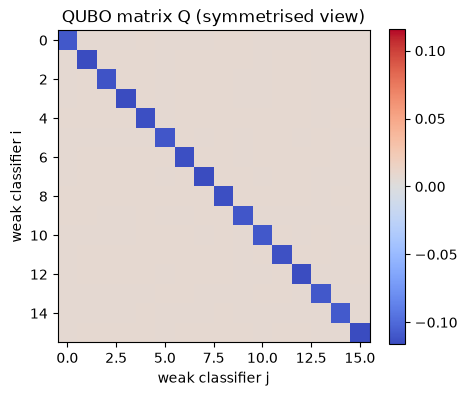

In [19]:
print(f"QUBO of the check in section 4: {Q16.shape[0]} binary variables (logical qubits on an annealer), "
      f"{int((np.triu(Q16, 1) != 0).sum())} non-zero couplers (fully connected); main model: {K_POOL} variables, {K_POOL * (K_POOL - 1) // 2} couplers.")
fig, ax = plt.subplots(figsize=(4.8, 4))
vmax = np.abs(Q16).max(); im = ax.imshow(Q16 + np.triu(Q16, 1).T, cmap="coolwarm", vmin=-vmax, vmax=vmax)
ax.set_title("QUBO matrix Q (symmetrised view)"); ax.set_xlabel("weak classifier j"); ax.set_ylabel("weak classifier i"); plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

## 9. Reading the paper critically

* **The quantum part is a solver, not a model.** QBoost is a classical ensemble whose *subset selection* is cast as a QUBO.
  Here a classical annealer solves the same QUBO equally well at this size (the 16-variable check reaches the exhaustive
  optimum), so the experiment says nothing about a quantum advantage in accuracy. It says that a sparse ensemble with
  binary weights is a cheap classifier.
* **What is compared in time?** QBoost on a cloud hybrid solver (which already runs classical code on the cloud side) against an
  un-tuned RBF-`SVC` on millions of frames. An RBF-SVC is the wrong tool at that size: its cost grows faster than linearly with
  the number of frames. The paper's own future-work list names RandomForest and AdaBoost, which are fast classical baselines
  and are included here; a linear model would be faster still. A "99 % time gain over SVC" therefore measures SVC's poor scaling
  at least as much as anything quantum.
* **Unspecified, yet decisive.** The paper gives no weak-classifier type, number of classifiers, `lambda`, solver time limit,
  SVC hyper-parameters or hardware. Training time depends directly on them; the Fuzzy QBoost time (25.7 s) is close to the DoS
  one (26.1 s), which looks like a solver time limit or fixed cloud latency rather than computation.
* **Easy data.** DoS is solved perfectly by almost anything: the injected ID is `0000` with an empty payload. The Fuzzy file
  is mostly detectable from the payload and ID codes. Those codes are first-appearance ranks, so late-appearing (never-seen)
  payloads look "new"; see the `strict` variant for how much of the accuracy depends on that.
* **Evaluation.** A random 80 / 20 split of consecutive CAN frames puts neighbouring frames of the same attack burst on both
  sides; the paper's own remark that metrics did not change between rounds is consistent with a very easy problem rather than
  with "low overfitting". No timing of the pre-processing, no confidence intervals, no real-time (streaming) test.
* **Metric convention.** Precision / recall in Table 3 are for the *normal* class. For an IDS the recall of the *attack*
  class matters more; it is reported here too (section 5.1).

## 10. Exercises

1. Replace the weak classifiers by depth-1 stumps (`TREE_DEPTH = 1`) and by depth-6 trees. How do accuracy, number of selected
   classifiers and the chosen `lambda` change? Why does the QUBO become denser to solve with more correlated classifiers?
2. Set `SA_READS` to 1 and `SA_SWEEPS` to 10 and rerun the 16-variable check. How often does simulated annealing miss the
   exhaustive optimum, and what does that say about using a noisy annealer?
3. Replace the `SVC` baseline by `LinearSVC` or logistic regression and redo the timing study. Is any "time gain" of QBoost left
   at the paper's data size?
4. Add `RPM_dataset.csv` / `gear_dataset.csv` (second GitHub zip, `Car-Hacking-Dataset-2.zip`) as the paper's future work
   suggests, using the same pipeline. Are the spoofing attacks as easy as DoS?
5. Split by time instead of randomly (train on the first 80 % of the log, test on the last 20 %) and use the `strict` encoding.
   Does the 97 to 99 % Fuzzy accuracy survive?

## Runtime

Measured on a shared 8-core laptop CPU (other jobs were running, so absolute times are noisy): the `FAST_MODE = True` path finishes in about 5 minutes (about 2 minutes once the CSV files are parsed and cached); the full `FAST_MODE = False` run (50,000 frames per round, 10 rounds, scaling study up to 40,000 training frames, 3 strict rounds) took **31 minutes** (main experiment 23 min, scaling study 3 min, strict variant 5 min). The last cell of section 8 prints the wall-clock time of the run. The timing comparison of section 6 is sensitive to machine load: the *ranking* and the scaling slopes are more reliable than single absolute seconds (for instance the QBoost training time was about 1 s per round in FAST_MODE and about 23 s in the full run, because the full run anneals K = 100 variables with 50 reads for 5 lambdas, on a busy machine).